In [1]:
# Useful starting lines
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

# Load the data

In [2]:
import datetime
from helpers import *

height, weight, gender = load_data(sub_sample=False, add_outlier=False)
x, mean_x, std_x = standardize(height)
y, tx = build_model_data(x, weight)

In [3]:
y.shape, tx.shape

((10000,), (10000, 2))

### NB: throughout this laboratory the data has the following format: 
  * there are **N = 10000** data entries
  * **y** represents the column vector containing weight information -- that which we wish to predict/the output (see also the first page of $\texttt{exercise02.pdf}$). Its **shape** is **(N,)**.
  * **tx** represents the matrix $\tilde{X}$ formed by laterally concatenating a column vector of 1s to the column vector of height information -- the input data (see also the first page of $\texttt{exercise02.pdf}$). Its **shape** is **(N,2)**.

# 1. Computing the Cost Function
Fill in the `compute_loss` function below:

In [4]:
### SOLUTION
def calculate_mse(e):
    """Calculate the mse for vector e."""
    return 1 / 2 * np.mean(e**2)


def calculate_mae(e):
    """Calculate the mae for vector e."""
    return np.mean(np.abs(e))


### TEMPLATE
### END SOLUTION


def compute_loss(y, tx, w):
    """Calculate the loss using either MSE or MAE.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        w: numpy array of shape=(2,). The vector of model parameters.

    Returns:
        the value of the loss (a scalar), corresponding to the input parameters w.
    """
    ### SOLUTION
    e = y - tx.dot(w)
    return calculate_mse(e)
    ### TEMPLATE
    # # ***************************************************
    # # INSERT YOUR CODE HERE
    # # TODO: compute loss by MSE
    # # ***************************************************
    # raise NotImplementedError
    ### END SOLUTION

# 2. Grid Search

Fill in the function `grid_search()` below:

In [5]:
# from costs import *


def grid_search(y, tx, grid_w0, grid_w1):
    """Algorithm for grid search.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        grid_w0: numpy array of shape=(num_grid_pts_w0, ). A 1D array containing num_grid_pts_w0 values of parameter w0 to be tested in the grid search.
        grid_w1: numpy array of shape=(num_grid_pts_w1, ). A 1D array containing num_grid_pts_w1 values of parameter w1 to be tested in the grid search.

    Returns:
        losses: numpy array of shape=(num_grid_pts_w0, num_grid_pts_w1). A 2D array containing the loss value for each combination of w0 and w1
    """

    losses = np.zeros((len(grid_w0), len(grid_w1)))
    ### SOLUTION
    # compute loss for each combinationof w0 and w1.
    for ind_row, row in enumerate(grid_w0):
        for ind_col, col in enumerate(grid_w1):
            w = np.array([row, col])
            losses[ind_row, ind_col] = compute_loss(y, tx, w)
    ### TEMPLATE
    # # ***************************************************
    # # INSERT YOUR CODE HERE
    # # TODO: compute loss for each combination of w0 and w1.
    # # ***************************************************
    # raise NotImplementedError
    ### END SOLUTION
    return losses

Let us play with the grid search demo now!

Grid Search: loss*=42.42448314678197, w0*=66.66666666666669, w1*=16.666666666666686, execution time=0.019 seconds


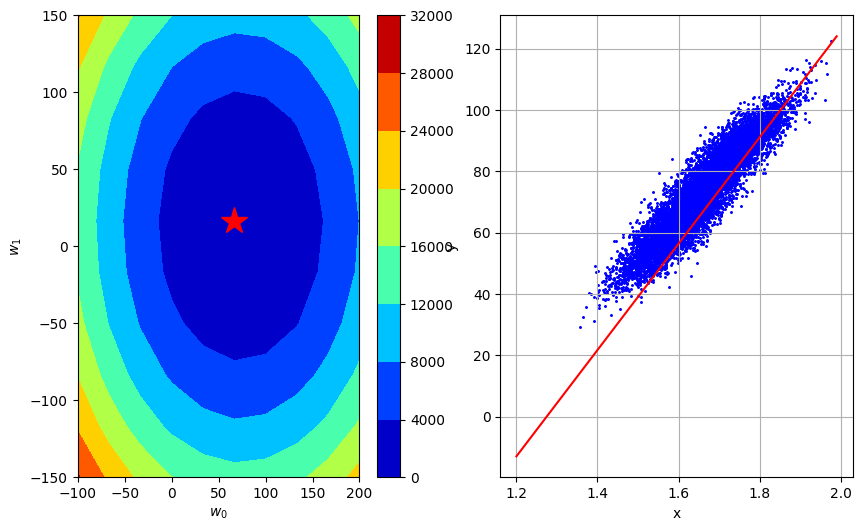

In [6]:
from grid_search import generate_w, get_best_parameters
from plots import grid_visualization

# Generate the grid of parameters to be swept
grid_w0, grid_w1 = generate_w(num_intervals=10)

# Start the grid search
start_time = datetime.datetime.now()
grid_losses = grid_search(y, tx, grid_w0, grid_w1)

# Select the best combinaison
loss_star, w0_star, w1_star = get_best_parameters(grid_w0, grid_w1, grid_losses)
end_time = datetime.datetime.now()
execution_time = (end_time - start_time).total_seconds()

# Print the results
print(
    "Grid Search: loss*={l}, w0*={w0}, w1*={w1}, execution time={t:.3f} seconds".format(
        l=loss_star, w0=w0_star, w1=w1_star, t=execution_time
    )
)

# Plot the results
fig = grid_visualization(grid_losses, grid_w0, grid_w1, mean_x, std_x, height, weight)
fig.set_size_inches(10.0, 6.0)
fig.savefig("grid_plot")  # Optional saving

# 3. Gradient Descent

Again, please fill in the functions `compute_gradient` below:

In [7]:
def compute_gradient(y, tx, w):
    """Computes the gradient at w.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        w: numpy array of shape=(2, ). The vector of model parameters.

    Returns:
        An numpy array of shape (2, ) (same shape as w), containing the gradient of the loss at w.
    """
    ### SOLUTION
    err = y - tx.dot(w)
    grad = -tx.T.dot(err) / len(err)
    return grad, err

    ### TEMPLATE
    # # ***************************************************
    # # INSERT YOUR CODE HERE
    # # TODO: compute gradient vector
    # # ***************************************************
    # raise NotImplementedError
    ### END SOLUTION

Please fill in the functions `gradient_descent` below:

In [8]:
def gradient_descent(y, tx, initial_w, max_iters, gamma):
    """The Gradient Descent (GD) algorithm.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        initial_w: numpy array of shape=(2, ). The initial guess (or the initialization) for the model parameters
        max_iters: a scalar denoting the total number of iterations of GD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of GD
        ws: a list of length max_iters + 1 containing the model parameters as numpy arrays of shape (2, ),
            for each iteration of GD (as well as the final weights)
    """
    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w
    for n_iter in range(max_iters):
        ### SOLUTION
        # compute loss, gradient
        grad, err = compute_gradient(y, tx, w)
        loss = calculate_mse(err)
        # update w by gradient descent
        w = w - gamma * grad

        ### TEMPLATE
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: compute gradient and loss
        # # ***************************************************
        # raise NotImplementedError
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: update w by gradient
        # # ***************************************************
        # raise NotImplementedError
        ### END SOLUTION

        # store w and loss
        ws.append(w)
        losses.append(loss)
        print(
            "GD iter. {bi}/{ti}: loss={l}, w0={w0}, w1={w1}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, w0=w[0], w1=w[1]
            )
        )

    return losses, ws

Test your gradient descent function through gradient descent demo shown below:

In [13]:
# from gradient_descent import *
from plots import gradient_descent_visualization

# Define the parameters of the algorithm.
max_iters = 50
gamma = 0.5

# Initialization
w_initial = np.array([0, 0])

# Start gradient descent.
start_time = datetime.datetime.now()
gd_losses, gd_ws = gradient_descent(y, tx, w_initial, max_iters, gamma)
end_time = datetime.datetime.now()

# Print result
exection_time = (end_time - start_time).total_seconds()
print("GD: execution time={t:.3f} seconds".format(t=exection_time))

GD iter. 0/49: loss=2792.236712759167, w0=36.646961001052624, w1=6.739856217494659
GD iter. 1/49: loss=709.5985940914106, w0=54.970441501578854, w1=10.109784326241904
GD iter. 2/49: loss=188.93906442447494, w0=64.13218175184198, w1=11.79474838061551
GD iter. 3/49: loss=58.77418200774081, w0=68.71305187697355, w1=12.637230407802297
GD iter. 4/49: loss=26.23296140355725, w0=71.00348693953934, w1=13.058471421395682
GD iter. 5/49: loss=18.097656252511353, w0=72.14870447082224, w1=13.26909192819237
GD iter. 6/49: loss=16.063829964749882, w0=72.72131323646369, w1=13.374402181590712
GD iter. 7/49: loss=15.55537339280952, w0=73.0076176192844, w1=13.427057308289882
GD iter. 8/49: loss=15.42825924982443, w0=73.15076981069477, w1=13.453384871639466
GD iter. 9/49: loss=15.396480714078157, w0=73.22234590639995, w1=13.466548653314257
GD iter. 10/49: loss=15.388536080141593, w0=73.25813395425254, w1=13.473130544151653
GD iter. 11/49: loss=15.386549921657448, w0=73.27602797817883, w1=13.47642148957035

In [11]:
pip install -U ipykernel


[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


interactive(children=(IntSlider(value=1, description='n_iter', max=51, min=1), Output()), _dom_classes=('widge…

<function __main__.plot_figure(n_iter)>

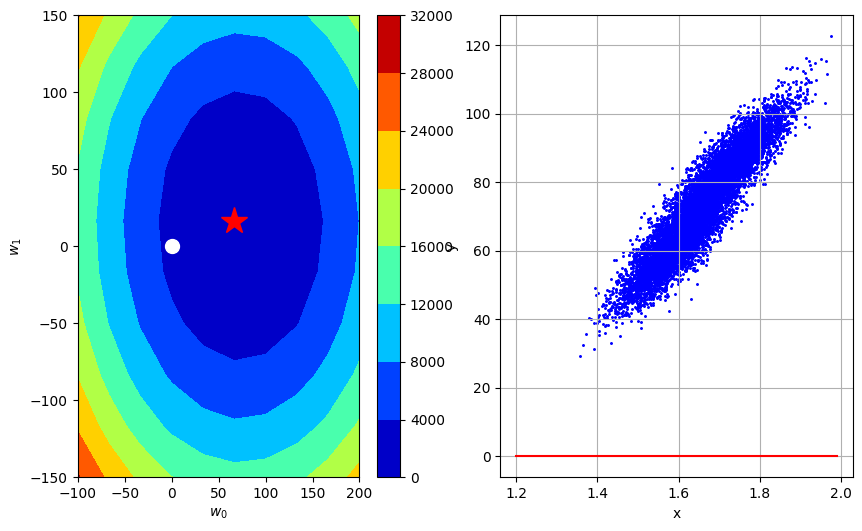

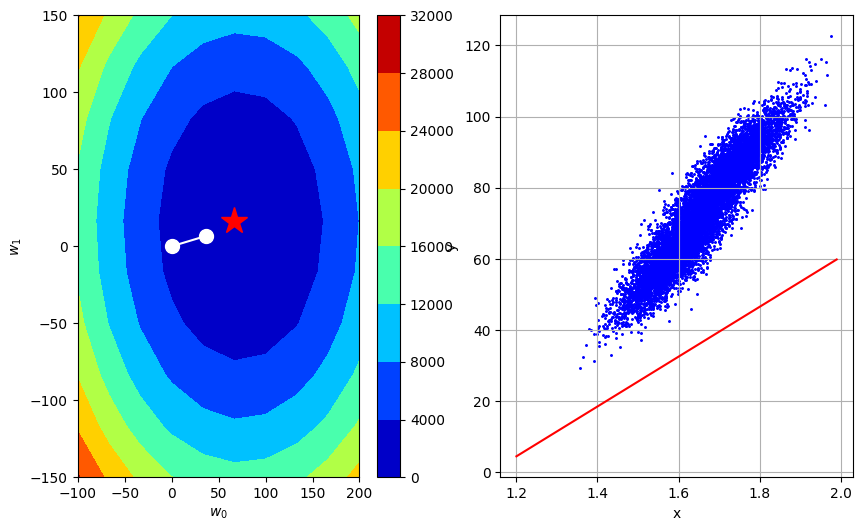

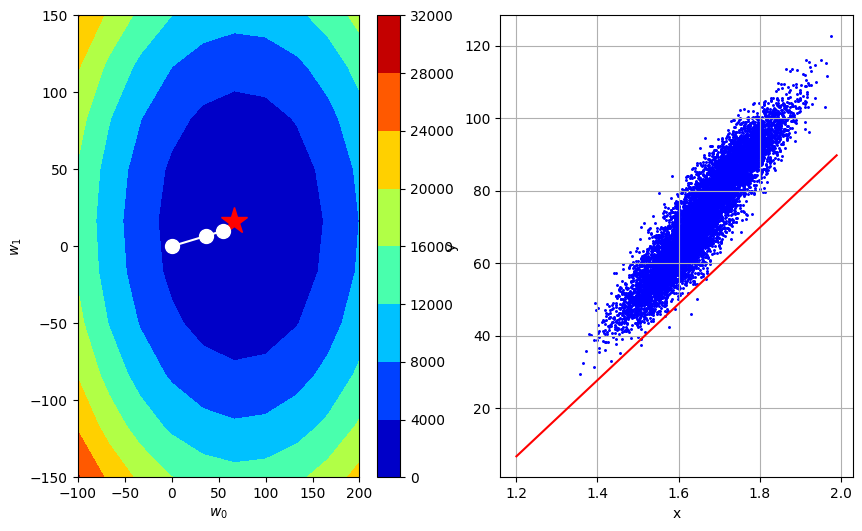

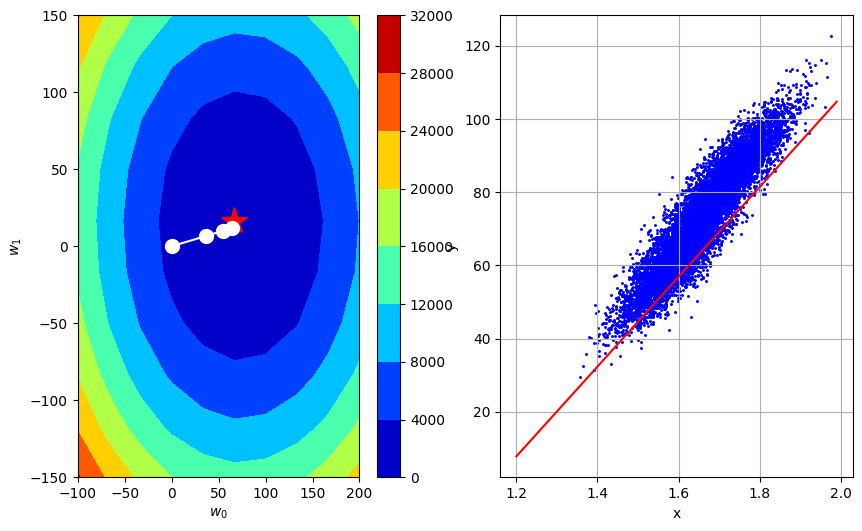

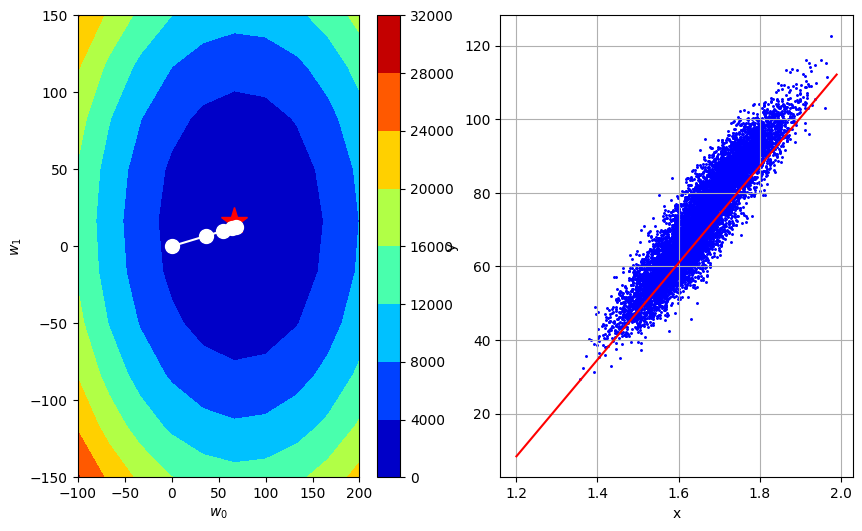

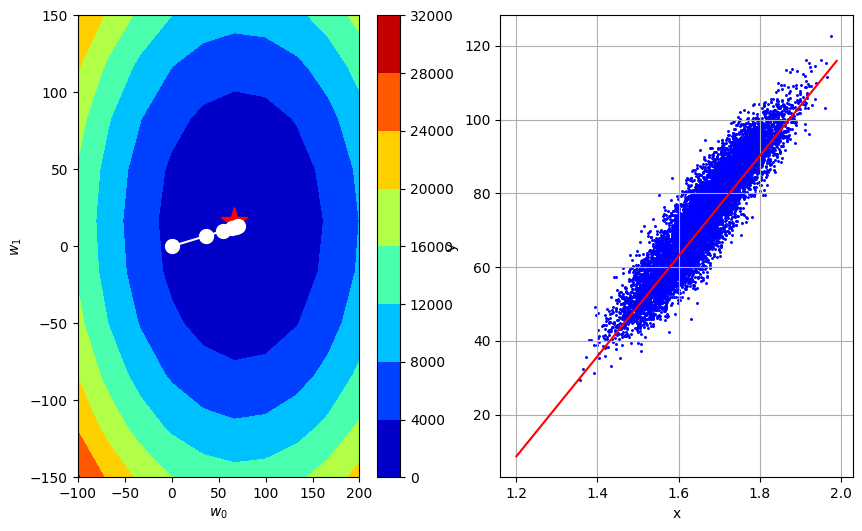

In [14]:
# Time Visualization
from ipywidgets import IntSlider, interact


def plot_figure(n_iter):
    fig = gradient_descent_visualization(
        gd_losses,
        gd_ws,
        grid_losses,
        grid_w0,
        grid_w1,
        mean_x,
        std_x,
        height,
        weight,
        n_iter,
    )
    fig.set_size_inches(10.0, 6.0)


interact(plot_figure, n_iter=IntSlider(min=1, max=len(gd_ws)))

# 4. Stochastic gradient descent

In [16]:
def compute_stoch_gradient(y, tx, w):
    """Compute a stochastic gradient at w from a data sample batch of size B, where B < N, and their corresponding labels.

    Args:
        y: numpy array of shape=(B, )
        tx: numpy array of shape=(B,2)
        w: numpy array of shape=(2, ). The vector of model parameters.

    Returns:
        A numpy array of shape (2, ) (same shape as w), containing the stochastic gradient of the loss at w.
    """

    ### SOLUTION
    err = y - tx.dot(w)
    grad = -tx.T.dot(err) / len(err)
    return grad, err

    ### TEMPLATE
    # # ***************************************************
    # # INSERT YOUR CODE HERE
    # # TODO: implement stochastic gradient computation. It's the same as the usual gradient.
    # # ***************************************************
    # raise NotImplementedError
    ### END SOLUTION


def stochastic_gradient_descent(y, tx, initial_w, batch_size, max_iters, gamma):
    """The Stochastic Gradient Descent algorithm (SGD).

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        initial_w: numpy array of shape=(2, ). The initial guess (or the initialization) for the model parameters
        batch_size: a scalar denoting the number of data points in a mini-batch used for computing the stochastic gradient
        max_iters: a scalar denoting the total number of iterations of SGD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of SGD
        ws: a list of length max_iters containing the model parameters as numpy arrays of shape (2, ), for each iteration of SGD
    """

    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w

    for n_iter in range(max_iters):
        ### SOLUTION
        for y_batch, tx_batch in batch_iter(
            y, tx, batch_size=batch_size, num_batches=1
        ):
            # compute a stochastic gradient and loss
            grad, _ = compute_stoch_gradient(y_batch, tx_batch, w)
            # update w through the stochastic gradient update
            w = w - gamma * grad
            # calculate loss
            loss = compute_loss(y, tx, w)
            # store w and loss
            ws.append(w)
            losses.append(loss)

        ### TEMPLATE
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: implement stochastic gradient descent.
        # # ***************************************************
        # raise NotImplementedError
        ### END SOLUTION

        print(
            "SGD iter. {bi}/{ti}: loss={l}, w0={w0}, w1={w1}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, w0=w[0], w1=w[1]
            )
        )
    return losses, ws

In [17]:
# from stochastic_gradient_descent import *

# Define the parameters of the algorithm.
max_iters = 50
gamma = 0.1
batch_size = 1

# Initialization
w_initial = np.array([0, 0])

# Start SGD.
start_time = datetime.datetime.now()
sgd_losses, sgd_ws = stochastic_gradient_descent(
    y, tx, w_initial, batch_size, max_iters, gamma
)
end_time = datetime.datetime.now()

# Print result
exection_time = (end_time - start_time).total_seconds()
print("SGD: execution time={t:.3f} seconds".format(t=exection_time))

SGD iter. 0/49: loss=2299.8699991595813, w0=7.231379469064034, w1=-0.8279322576790517
SGD iter. 1/49: loss=2048.9329985834456, w0=12.149084283285845, w1=-4.642181554560703
SGD iter. 2/49: loss=1387.6562099312853, w0=21.189769462741538, w1=8.030131508014868
SGD iter. 3/49: loss=1105.5382479545458, w0=26.603182268374034, w1=14.008430969199146
SGD iter. 4/49: loss=899.5273179170493, w0=31.29479968735741, w1=15.566955805394318
SGD iter. 5/49: loss=735.6759512920377, w0=35.34211404451667, w1=13.970018050643397
SGD iter. 6/49: loss=582.5392165899668, w0=39.625077381979, w1=14.32561986968785
SGD iter. 7/49: loss=483.2882029001441, w0=42.70353405388097, w1=13.660806995293392
SGD iter. 8/49: loss=397.9265301274562, w0=45.63558485134389, w1=13.79223534946812
SGD iter. 9/49: loss=314.7941725058354, w0=49.20049218912788, w1=9.199150658638851
SGD iter. 10/49: loss=274.7020624444724, w0=51.06788870146159, w1=8.516266769932379
SGD iter. 11/49: loss=187.08627344164444, w0=54.763808902089764, w1=13.668

In [13]:
# Time Visualization
from ipywidgets import IntSlider, interact


def plot_figure(n_iter):
    fig = gradient_descent_visualization(
        sgd_losses,
        sgd_ws,
        grid_losses,
        grid_w0,
        grid_w1,
        mean_x,
        std_x,
        height,
        weight,
        n_iter,
    )
    fig.set_size_inches(10.0, 6.0)


interact(plot_figure, n_iter=IntSlider(min=1, max=len(sgd_ws)))

interactive(children=(IntSlider(value=1, description='n_iter', max=51, min=1), Output()), _dom_classes=('widge…

<function __main__.plot_figure(n_iter)>

# 5. Effect of Outliers and MAE Cost Function

In [14]:
import datetime
from helpers import *

### SOLUTION
height, weight, gender = load_data(sub_sample=True, add_outlier=True)
### TEMPLATE
## ***************************************************
## INSERT YOUR CODE HERE
## TODO: reload the data by subsampling first, then by subsampling and adding outliers
## ***************************************************
# raise NotImplementedError
### END SOLUTION

x, mean_x, std_x = standardize(height)
y, tx = build_model_data(x, weight)

In [15]:
y.shape, tx.shape

((202,), (202, 2))

In [16]:
from plots import gradient_descent_visualization

# Define the parameters of the algorithm.
max_iters = 50
gamma = 0.7

# Initialization
w_initial = np.array([0, 0])

# Start gradient descent.
start_time = datetime.datetime.now()

### SOLUTION
gd_losses, gd_ws = gradient_descent(y, tx, w_initial, max_iters, gamma)
### TEMPLATE
# # ***************************************************
# # INSERT YOUR CODE HERE
# # TODO: fit the model to the subsampled data / subsampled data with outliers and visualize the cloud of points
# #       and the model fit
# # ***************************************************
# raise NotImplementedError
### END SOLUTION


end_time = datetime.datetime.now()

# Print result
exection_time = (end_time - start_time).total_seconds()
print("GD: execution time={t:.3f} seconds".format(t=exection_time))

GD iter. 0/49: loss=2869.8351145358524, w0=51.84746409844842, w1=7.7244264061924195
GD iter. 1/49: loss=318.2821247015965, w0=67.40170332798297, w1=10.041754328050114
GD iter. 2/49: loss=88.6423556165128, w0=72.06797509684336, w1=10.736952704607411
GD iter. 3/49: loss=67.9747763988552, w0=73.46785662750146, w1=10.945512217574597
GD iter. 4/49: loss=66.11469426926604, w0=73.88782108669889, w1=11.00808007146475
GD iter. 5/49: loss=65.94728687760302, w0=74.01381042445813, w1=11.026850427631798
GD iter. 6/49: loss=65.93222021235334, w0=74.0516072257859, w1=11.032481534481914
GD iter. 7/49: loss=65.93086421248087, w0=74.06294626618423, w1=11.034170866536945
GD iter. 8/49: loss=65.93074217249236, w0=74.06634797830372, w1=11.034677666153454
GD iter. 9/49: loss=65.93073118889338, w0=74.06736849193958, w1=11.034829706038408
GD iter. 10/49: loss=65.93073020036948, w0=74.06767464603033, w1=11.034875318003895
GD iter. 11/49: loss=65.93073011140233, w0=74.06776649225755, w1=11.034889001593541
GD it

In [17]:
# Time Visualization
from ipywidgets import IntSlider, interact


def plot_figure(n_iter):
    fig = gradient_descent_visualization(
        gd_losses,
        gd_ws,
        grid_losses,
        grid_w0,
        grid_w1,
        mean_x,
        std_x,
        height,
        weight,
        n_iter,
    )
    fig.set_size_inches(10.0, 6.0)


interact(plot_figure, n_iter=IntSlider(min=1, max=len(gd_ws)))

interactive(children=(IntSlider(value=1, description='n_iter', max=51, min=1), Output()), _dom_classes=('widge…

<function __main__.plot_figure(n_iter)>

# 6. Subgradient descent

In [18]:
def compute_subgradient_mae(y, tx, w):
    """Compute a subgradient of the MAE at w.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        w: numpy array of shape=(2, ). The vector of model parameters.

    Returns:
        A numpy array of shape (2, ) (same shape as w), containing the subgradient of the MAE at w.
    """
    ### SOLUTION
    err = y - tx.dot(w)
    grad = -np.dot(tx.T, np.sign(err)) / len(err)
    return grad, err
    ### TEMPLATE
    # # ***************************************************
    # # INSERT YOUR CODE HERE
    # # TODO: compute subgradient gradient vector for MAE
    # # ***************************************************
    # raise NotImplementedError
    ### END SOLUTION

In [19]:
def subgradient_descent(y, tx, initial_w, max_iters, gamma):
    """The SubGradient Descent (SubGD) algorithm.

    Args:
        y: numpy array of shape=(N, )
        tx: numpy array of shape=(N,2)
        initial_w: numpy array of shape=(2, ). The initial guess (or the initialization) for the model parameters
        max_iters: a scalar denoting the total number of iterations of GD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of SubGD
        ws: a list of length max_iters containing the model parameters as numpy arrays of shape (2, ), for each iteration of SubGD
    """
    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w
    for n_iter in range(max_iters):
        ### SOLUTION
        # compute loss, gradient
        grad, err = compute_subgradient_mae(y, tx, w)
        loss = calculate_mae(err)
        # gradient w by descent update
        w = w - gamma * grad
        # store w and loss

        ### TEMPLATE
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: compute subgradient and loss
        # # ***************************************************
        # raise NotImplementedError
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: update w by subgradient
        # # ***************************************************
        # raise NotImplementedError
        ### END SOLUTION

        ws.append(w)
        losses.append(loss)
        print(
            "SubGD iter. {bi}/{ti}: loss={l}, w0={w0}, w1={w1}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, w0=w[0], w1=w[1]
            )
        )

    return losses, ws

In [20]:
# Define the parameters of the algorithm.
max_iters = 500
gamma = 0.7
batch_size = 1

# Initialization
w_initial = np.array([0, 0])

# Start SubSGD.
start_time = datetime.datetime.now()
subgd_losses, subgd_ws = subgradient_descent(y, tx, w_initial, max_iters, gamma)
end_time = datetime.datetime.now()

# Print result
exection_time = (end_time - start_time).total_seconds()
print("SubGD: execution time={t:.3f} seconds".format(t=exection_time))

SubGD iter. 0/499: loss=73.29392200210518, w0=0.7, w1=2.666453724486928e-15
SubGD iter. 1/499: loss=72.59392200210519, w0=1.4, w1=5.332907448973856e-15
SubGD iter. 2/499: loss=71.89392200210519, w0=2.0999999999999996, w1=7.999361173460784e-15
SubGD iter. 3/499: loss=71.19392200210518, w0=2.8, w1=1.0665814897947712e-14
SubGD iter. 4/499: loss=70.49392200210517, w0=3.5, w1=1.333226862243464e-14
SubGD iter. 5/499: loss=69.79392200210518, w0=4.2, w1=1.5998722346921567e-14
SubGD iter. 6/499: loss=69.09392200210517, w0=4.9, w1=1.8665176071408495e-14
SubGD iter. 7/499: loss=68.39392200210517, w0=5.6000000000000005, w1=2.1331629795895423e-14
SubGD iter. 8/499: loss=67.69392200210517, w0=6.300000000000001, w1=2.399808352038235e-14
SubGD iter. 9/499: loss=66.99392200210517, w0=7.000000000000001, w1=2.666453724486928e-14
SubGD iter. 10/499: loss=66.29392200210518, w0=7.700000000000001, w1=2.9330990969356204e-14
SubGD iter. 11/499: loss=65.59392200210519, w0=8.4, w1=3.1997444693843135e-14
SubGD it

interactive(children=(IntSlider(value=1, description='n_iter', max=501, min=1), Output()), _dom_classes=('widg…

<function __main__.plot_figure(n_iter)>

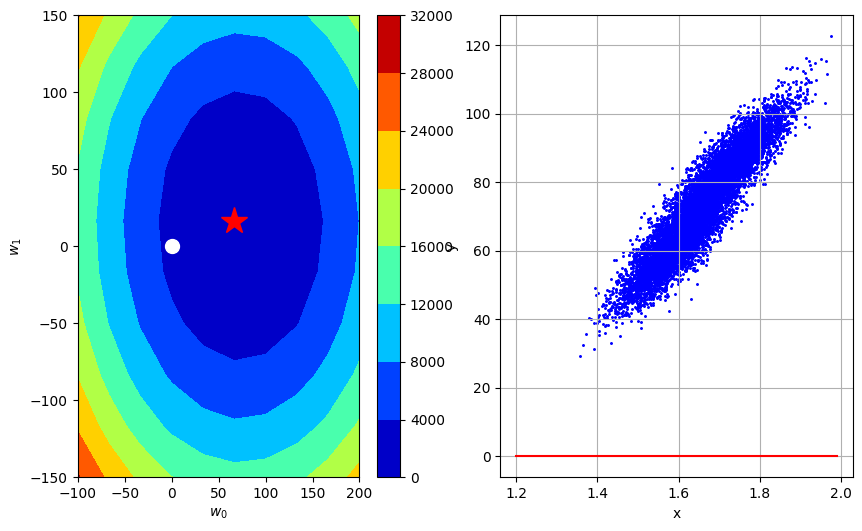

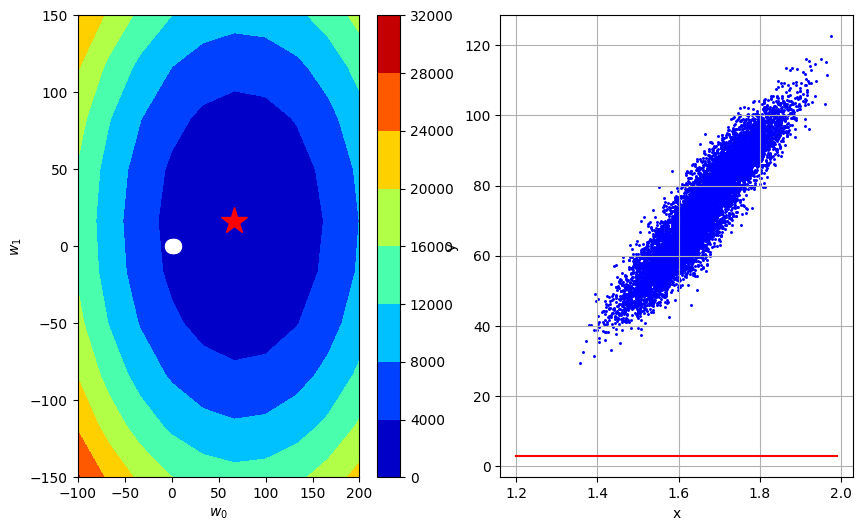

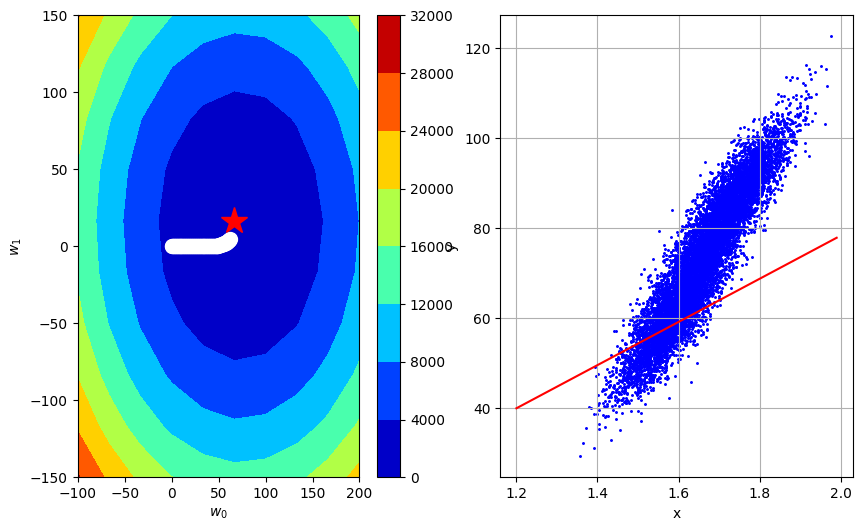

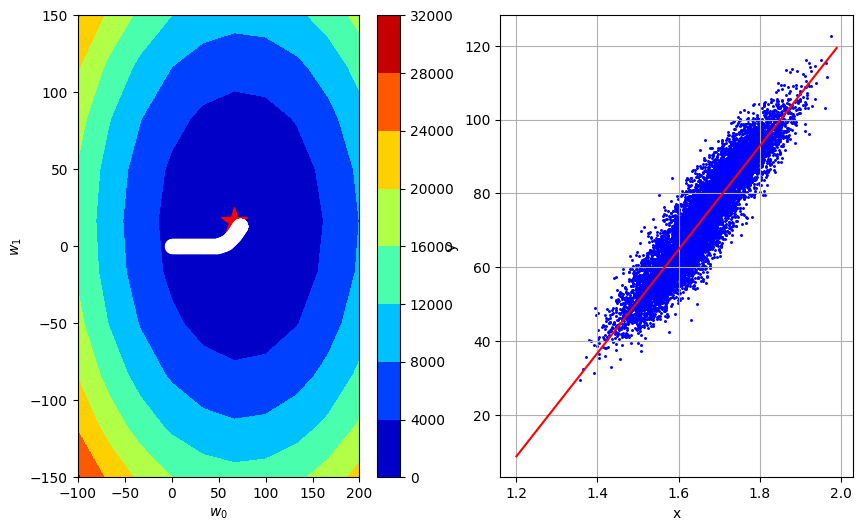

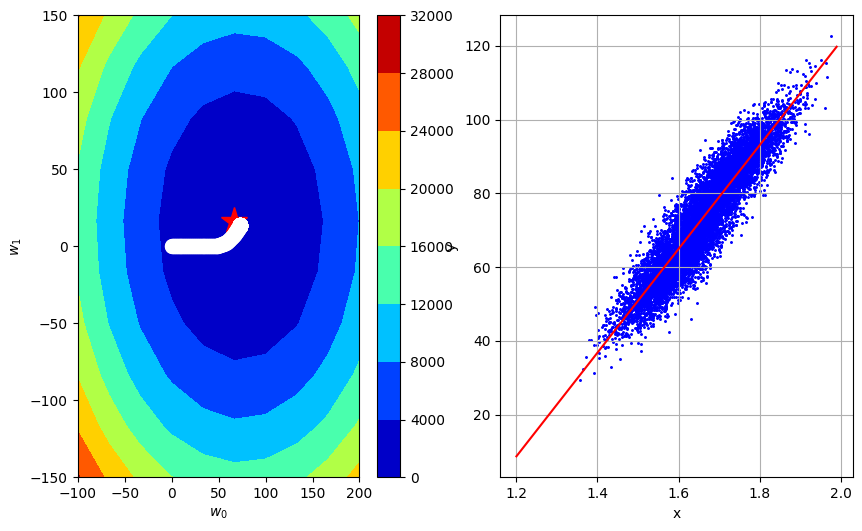

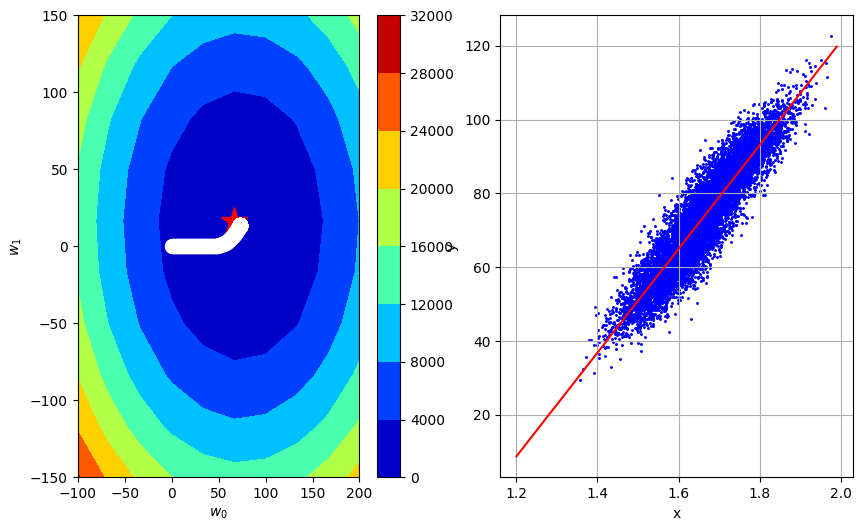

In [21]:
from ipywidgets import IntSlider, interact


def plot_figure(n_iter):
    fig = gradient_descent_visualization(
        subgd_losses,
        subgd_ws,
        grid_losses,
        grid_w0,
        grid_w1,
        mean_x,
        std_x,
        height,
        weight,
        n_iter,
    )
    fig.set_size_inches(10.0, 6.0)


interact(plot_figure, n_iter=IntSlider(min=1, max=len(subgd_ws)))

# Stochastic Subgradient Descent

**NB** for the computation of the subgradient you can reuse the `compute_subgradient` method that you implemented above, just making sure that you pass in a minibatch as opposed to the full data.

In [22]:
def stochastic_subgradient_descent(y, tx, initial_w, batch_size, max_iters, gamma):
    """Compute a stochastic subgradient at w from a data sample batch of size B, where B < N, and their corresponding labels.

    Args:
        y: numpy array of shape=(B, )
        tx: numpy array of shape=(B,2)
        initial_w: numpy array of shape=(2, ). The initial guess (or the initialization) for the model parameters
        batch_size: a scalar denoting the number of data points in a mini-batch used for computing the stochastic subgradient
        max_iters: a scalar denoting the total number of iterations of SubSGD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of SubSGD
        ws: a list of length max_iters containing the model parameters as numpy arrays of shape (2, ), for each iteration of SubSGD
    """

    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w

    for n_iter in range(max_iters):
        ### SOLUTION
        for y_batch, tx_batch in batch_iter(
            y, tx, batch_size=batch_size, num_batches=1
        ):
            # compute a stochastic subgradient and loss
            grad, err = compute_subgradient_mae(y_batch, tx_batch, w)
            # update w through the stochastic subgradient update
            w = w - gamma * grad
            # calculate loss
            loss = calculate_mae(err)
            # store w and loss
            ws.append(w)
            losses.append(loss)

        ### TEMPLATE
        # # ***************************************************
        # # INSERT YOUR CODE HERE
        # # TODO: implement stochastic subgradient descent.
        # # ***************************************************
        # raise NotImplementedError
        ### END SOLUTION

        print(
            "SubSGD iter. {bi}/{ti}: loss={l}, w0={w0}, w1={w1}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, w0=w[0], w1=w[1]
            )
        )
    return losses, ws

In [23]:
# Define the parameters of the algorithm.
max_iters = 500
gamma = 0.7
batch_size = 1

# Initialization
w_initial = np.array([0, 0])

# Start SubSGD.
start_time = datetime.datetime.now()
subsgd_losses, subsgd_ws = stochastic_subgradient_descent(
    y, tx, w_initial, batch_size, max_iters, gamma
)
end_time = datetime.datetime.now()

# Print result
exection_time = (end_time - start_time).total_seconds()
print("SubSGD: execution time={t:.3f} seconds".format(t=exection_time))

SubSGD iter. 0/499: loss=61.176769716949444, w0=0.7, w1=-0.42578614729073927
SubSGD iter. 1/499: loss=88.01184769210465, w0=1.4, w1=0.3201995062966577
SubSGD iter. 2/499: loss=76.66475829417655, w0=2.0999999999999996, w1=0.5226363963376568
SubSGD iter. 3/499: loss=92.46960137823967, w0=2.8, w1=1.7173752334420822
SubSGD iter. 4/499: loss=61.162562433493946, w0=3.5, w1=1.5669185569909547
SubSGD iter. 5/499: loss=87.26502181203385, w0=4.2, w1=2.4002561395505317
SubSGD iter. 6/499: loss=81.26090797775943, w0=4.9, w1=2.866838265517107
SubSGD iter. 7/499: loss=88.88551369491859, w0=5.6000000000000005, w1=3.879276603383528
SubSGD iter. 8/499: loss=69.44984886817775, w0=6.300000000000001, w1=4.234304080913354
SubSGD iter. 9/499: loss=68.82061884611149, w0=7.000000000000001, w1=4.499089190104122
SubSGD iter. 10/499: loss=53.06304336027652, w0=7.700000000000001, w1=3.5222917111622034
SubSGD iter. 11/499: loss=44.31361789586226, w0=8.4, w1=2.3963592976610326
SubSGD iter. 12/499: loss=47.925948214

In [24]:
from ipywidgets import IntSlider, interact


def plot_figure(n_iter):
    fig = gradient_descent_visualization(
        subsgd_losses,
        subsgd_ws,
        grid_losses,
        grid_w0,
        grid_w1,
        mean_x,
        std_x,
        height,
        weight,
        n_iter,
    )
    fig.set_size_inches(10.0, 6.0)


interact(plot_figure, n_iter=IntSlider(min=1, max=len(subsgd_ws)))

interactive(children=(IntSlider(value=1, description='n_iter', max=501, min=1), Output()), _dom_classes=('widg…

<function __main__.plot_figure(n_iter)>